/tmp/ipython-input-254004214.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
/tmp/ipython-input-254004214.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
/tmp/ipython-input-254004214.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
/tmp/ipython-input-254004214.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
/tmp/ipython-input-254004214.py:36: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Clo


Markov Transition Matrix:
From Early_Recovery: {'Early_Recovery': 0.9705197827773467, 'Mid_Cycle_Expansion': 0.008533747090768037, 'Late_Cycle_Peak': 0.0023273855702094647, 'Recession_Contraction': 0.018619084561675717}
From Mid_Cycle_Expansion: {'Early_Recovery': 0.008516678495386799, 'Mid_Cycle_Expansion': 0.971611071682044, 'Late_Cycle_Peak': 0.0113555713271824, 'Recession_Contraction': 0.008516678495386799}
From Late_Cycle_Peak: {'Early_Recovery': 0.0, 'Mid_Cycle_Expansion': 0.036053130929791274, 'Late_Cycle_Peak': 0.9639468690702088, 'Recession_Contraction': 0.0}
From Recession_Contraction: {'Early_Recovery': 0.06896551724137931, 'Mid_Cycle_Expansion': 0.026525198938992044, 'Late_Cycle_Peak': 0.0, 'Recession_Contraction': 0.9045092838196287}
Early Recovery: Sharpe Ratio = 0.7863, Max Drawdown = 37.71%
Mid Cycle Expansion: Sharpe Ratio = 0.7386, Max Drawdown = 40.13%
Late Cycle Peak: Sharpe Ratio = 0.1842, Max Drawdown = 70.92%
Recession Contraction: Sharpe Ratio = 0.7818, Max Dra

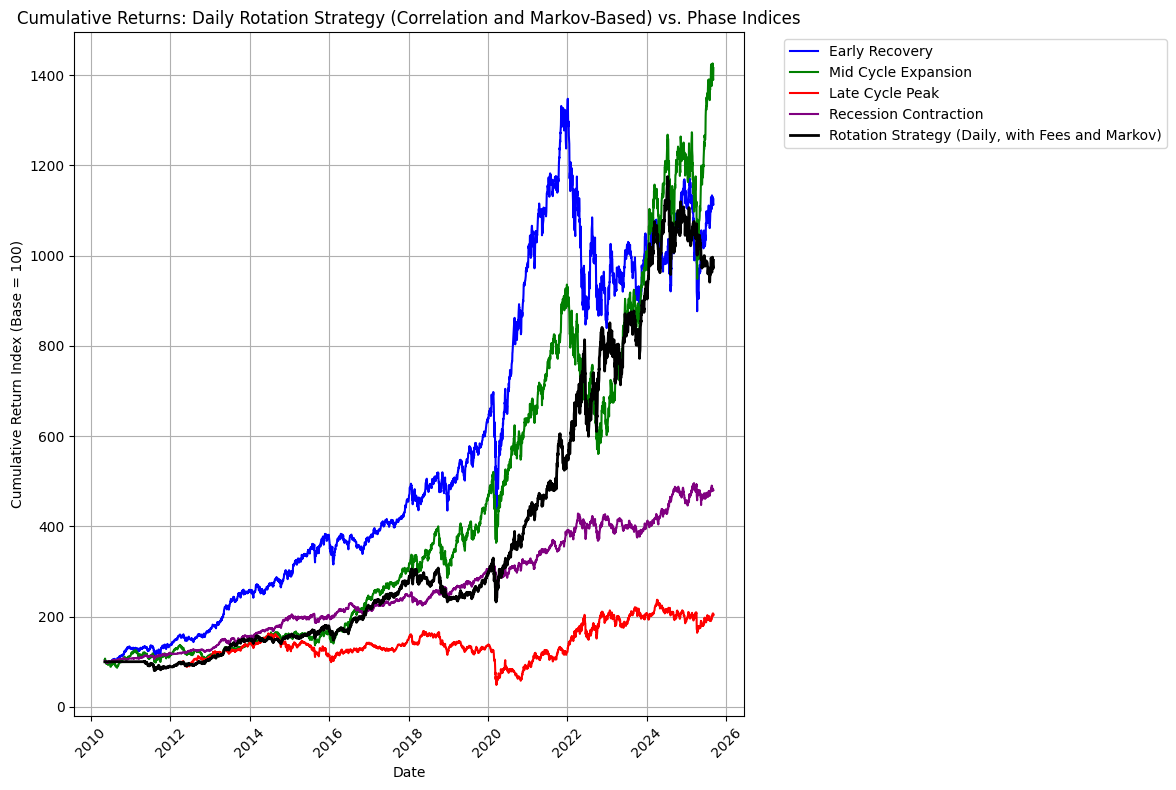

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Define sectors and their representative stocks
sectors = {
    'Technology': ['AAPL', 'MSFT', 'GOOGL', 'NVDA', 'AMD', 'INTC', 'CSCO', 'ORCL', 'QCOM', 'IBM'],
    'Financials': ['JPM', 'BAC', 'WFC', 'GS', 'MS', 'C', 'BLK', 'SCHW', 'AXP', 'USB'],
    'Healthcare': ['JNJ', 'PFE', 'MRK', 'GILD', 'BMY', 'ABBV', 'AMGN', 'LLY', 'CVS', 'UNH'],
    'Consumer_Discretionary': ['AMZN', 'TSLA', 'HD', 'NKE', 'MCD', 'SBUX', 'TGT', 'LOW', 'DIS', 'F'],
    'Energy': ['XOM', 'CVX', 'BP', 'SLB', 'KMI', 'COP', 'OXY', 'VLO', 'PSX', 'HAL'],
    'Industrials': ['CAT', 'GE', 'MMM', 'BA', 'HON', 'UNP', 'RTX', 'DE', 'LMT', 'UPS'],
    'Consumer_Staples': ['PG', 'KO', 'PEP', 'WMT', 'CL', 'COST', 'MO', 'KMB', 'GIS', 'KR'],
    'Utilities': ['DUK', 'SO', 'NEE', 'AEP', 'EXC', 'D', 'ED', 'PEG', 'XEL', 'SRE'],
    'Materials': ['PPG', 'DD', 'NEM', 'FCX', 'LYB', 'ECL', 'APD', 'SHW', 'VMC', 'MLM']
}

# Define economic cycle phases and associated sectors
economic_phases = {
     'Early_Recovery': ['Consumer_Discretionary'],
        'Mid_Cycle_Expansion': ['Technology'],
        'Late_Cycle_Peak': ['Energy'],
        'Recession_Contraction': ['Healthcare', 'Consumer_Staples', 'Utilities']
}

# Define the time period for data and transaction fee
end_date = datetime.now()
start_date = end_date - timedelta(days=5600)
transaction_fee = 0.001  # 0.1% fee in log return terms
window = 252  # Rolling window for ranking (e.g., 252 trading days ~ 1 year)

# Fetch stock data from yfinance
def fetch_stock_data(tickers, start_date, end_date):
    data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
    return data

# Calculate equal-weighted sector index daily log returns
def calculate_sector_index_returns(data, sector_name):
    log_returns = np.log(data / data.shift(1)).dropna()
    weights = [1/len(data.columns)] * len(data.columns)
    index_log_returns = (log_returns * weights).sum(axis=1)
    # print(f"{sector_name} returns length: {len(index_log_returns)}")
    return index_log_returns

# Calculate phase index daily log returns
def calculate_phase_index_returns(sector_indices, phase_sectors, phase_name):
    phase_data = pd.DataFrame({sector: sector_indices[sector] for sector in phase_sectors})
    weights = [1/len(phase_sectors)] * len(phase_sectors)
    phase_log_returns = (phase_data * weights).sum(axis=1)
    # print(f"{phase_name} returns length: {len(phase_log_returns)}")
    return phase_log_returns

# Calculate Markov chain transition probabilities
def calculate_markov_transitions(top_phase):
    phases = list(economic_phases.keys())
    transition_counts = {p: {q: 0 for q in phases} for p in phases}
    total_transitions = {p: 0 for p in phases}

    prev_phase = None
    for phase in top_phase:
        if pd.isna(phase) or prev_phase is None or pd.isna(prev_phase):
            prev_phase = phase
            continue
        transition_counts[prev_phase][phase] += 1
        total_transitions[prev_phase] += 1
        prev_phase = phase

    transition_matrix = {p: {q: 0.0 for q in phases} for p in phases}
    for p in phases:
        total = total_transitions[p]
        if total > 0:
            for q in phases:
                transition_matrix[p][q] = transition_counts[p][q] / total
        else:
            for q in phases:
                transition_matrix[p][q] = 1.0 / len(phases)

    return transition_matrix

# Calculate cumulative returns for phase indices
def calculate_phase_index_cumulative(phase_returns):
    phase_cumulative = {}
    for phase, returns in phase_returns.items():
        phase_cumulative[phase] = np.exp(returns.cumsum()) * 100
    return phase_cumulative

# Calculate strategy cumulative returns with transaction fees and Markov chain
def calculate_strategy_cumulative(phase_returns):
    returns_df = pd.DataFrame(phase_returns)
    # Calculate rolling means using only past data (shift(1) to exclude current day)
    rolling_means = returns_df.shift(1).rolling(window=window, min_periods=window).mean()
    # Drop rows where all means are NaN
    rolling_means = rolling_means.dropna(how='all')
    # Rank phases (1 = highest mean return)
    ranks = rolling_means.rank(axis=1, method='min', ascending=False)
    top_phase = ranks.idxmin(axis=1)

    # Calculate Markov chain transition probabilities
    transition_matrix = calculate_markov_transitions(top_phase)

    # Initialize strategy returns
    strategy_returns = pd.Series(0.0, index=returns_df.index)
    prev_phase = None
    for date in returns_df.index:
        if date in top_phase.index and not pd.isna(top_phase[date]):
            current_phase = top_phase[date]
            # Apply returns for the current phase, weighted by Markov probability
            if prev_phase is not None:
                prob_weight = transition_matrix[prev_phase][current_phase] if prev_phase in transition_matrix else 1.0
                strategy_returns.loc[date] = returns_df.loc[date, current_phase] * prob_weight
                if current_phase != prev_phase:
                    strategy_returns.loc[date] -= transaction_fee
            else:
                strategy_returns.loc[date] = returns_df.loc[date, current_phase]
            prev_phase = current_phase
    strategy_cumulative = np.exp(strategy_returns.cumsum()) * 100
    # print(f"Strategy cumulative returns length: {len(strategy_cumulative)}")
    print("\nMarkov Transition Matrix:")
    for p in transition_matrix:
        print(f"From {p}: {transition_matrix[p]}")
    return strategy_returns, strategy_cumulative

# Calculate Sharpe Ratio and Maximum Drawdown
def calculate_metrics(phase_returns, strategy_returns):
    metrics = {}
    annualization_factor = 252
    for phase, returns in phase_returns.items():
        mean_return = returns.mean() * annualization_factor
        std_return = returns.std() * np.sqrt(annualization_factor)
        sharpe_ratio = mean_return / std_return if std_return != 0 else np.nan
        cumulative_returns = np.exp(returns.cumsum()) * 100
        running_max = cumulative_returns.cummax()
        drawdown = (running_max - cumulative_returns) / running_max
        max_dd = drawdown.max()
        metrics[phase] = {'Sharpe Ratio': sharpe_ratio, 'Max Drawdown (%)': max_dd * 100}
        print(f"{phase.replace('_', ' ')}: Sharpe Ratio = {sharpe_ratio:.4f}, Max Drawdown = {max_dd*100:.2f}%")
    mean_return = strategy_returns.mean() * annualization_factor
    std_return = strategy_returns.std() * np.sqrt(annualization_factor)
    sharpe_ratio = mean_return / std_return if std_return != 0 else np.nan
    cumulative_returns = np.exp(strategy_returns.cumsum()) * 100
    running_max = cumulative_returns.cummax()
    drawdown = (running_max - cumulative_returns) / running_max
    max_dd = drawdown.max()
    metrics['Strategy'] = {'Sharpe Ratio': sharpe_ratio, 'Max Drawdown (%)': max_dd * 100}
    print(f"Rotation Strategy (Daily, with Fees and Markov): Sharpe Ratio = {sharpe_ratio:.4f}, Max Drawdown = {max_dd*100:.2f}%")
    return metrics

# Plot cumulative returns
def plot_cumulative_returns(phase_cumulative, strategy_cumulative):
    plt.figure(figsize=(12, 8))
    colors = {
        'Early_Recovery': 'blue',
        'Mid_Cycle_Expansion': 'green',
        'Late_Cycle_Peak': 'red',
        'Recession_Contraction': 'purple'
    }
    for phase, cumulative_data in phase_cumulative.items():
        plt.plot(cumulative_data.index, cumulative_data, label=phase.replace('_', ' '), color=colors[phase])
    plt.plot(strategy_cumulative.index, strategy_cumulative, label='Rotation Strategy (Daily, with Fees and Markov)', color='black', linewidth=2)
    plt.title('Cumulative Returns: Daily Rotation Strategy (Correlation and Markov-Based) vs. Phase Indices')
    plt.xlabel('Date')
    plt.ylabel('Cumulative Return Index (Base = 100)')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Main execution
if __name__ == "__main__":
    sector_indices = {}
    for sector, tickers in sectors.items():
        stock_data = fetch_stock_data(tickers, start_date, end_date)
        # print(f"\nData lengths for {sector} stocks:")
        for ticker in stock_data.columns:
            data_length = len(stock_data[ticker].dropna())
            # print(f"{ticker}: {data_length} data points")
        sector_indices[sector] = calculate_sector_index_returns(stock_data, sector)

    phase_returns = {}
    for phase, phase_sectors in economic_phases.items():
        phase_returns[phase] = calculate_phase_index_returns(sector_indices, phase_sectors, phase)

    phase_cumulative = calculate_phase_index_cumulative(phase_returns)
    strategy_returns, strategy_cumulative = calculate_strategy_cumulative(phase_returns)
    metrics = calculate_metrics(phase_returns, strategy_returns)
    plot_cumulative_returns(phase_cumulative, strategy_cumulative)

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from scipy.optimize import minimize

# Define sectors and their representative stocks
sectors = {
    'Technology': ['AAPL', 'MSFT', 'GOOGL', 'NVDA', 'AMD', 'INTC', 'CSCO', 'ORCL', 'QCOM', 'IBM'],
    'Financials': ['JPM', 'BAC', 'WFC', 'GS', 'MS', 'C', 'BLK', 'SCHW', 'AXP', 'USB'],
    'Healthcare': ['JNJ', 'PFE', 'MRK', 'GILD', 'BMY', 'ABBV', 'AMGN', 'LLY', 'CVS', 'UNH'],
    'Consumer_Discretionary': ['AMZN', 'TSLA', 'HD', 'NKE', 'MCD', 'SBUX', 'TGT', 'LOW', 'DIS', 'F'],
    'Energy': ['XOM', 'CVX', 'BP', 'SLB', 'KMI', 'COP', 'OXY', 'VLO', 'PSX', 'HAL'],
    'Industrials': ['CAT', 'GE', 'MMM', 'BA', 'HON', 'UNP', 'RTX', 'DE', 'LMT', 'UPS'],
    'Consumer_Staples': ['PG', 'KO', 'PEP', 'WMT', 'CL', 'COST', 'MO', 'KMB', 'GIS', 'KR'],
    'Utilities': ['DUK', 'SO', 'NEE', 'AEP', 'EXC', 'D', 'ED', 'PEG', 'XEL', 'SRE'],
    'Materials': ['PPG', 'DD', 'NEM', 'FCX', 'LYB', 'ECL', 'APD', 'SHW', 'VMC', 'MLM']
}

# Define economic cycle phases and associated sectors
economic_phases = {
    'Early_Recovery': ['Consumer_Discretionary'],
    'Mid_Cycle_Expansion': ['Technology'],
    'Late_Cycle_Peak': ['Energy'],
    'Recession_Contraction': ['Healthcare', 'Consumer_Staples', 'Utilities']
}

# Define the time period for data and transaction fee
end_date = datetime.now()
start_date = end_date - timedelta(days=5600)
transaction_fee = 0.001  # 0.1% fee in log return terms
window = 252  # Rolling window for ranking and MVO (e.g., 252 trading days ~ 1 year)

# Fetch stock data from yfinance
def fetch_stock_data(tickers, start_date, end_date):
    data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']
    return data

# MVO objective function: negative Sharpe ratio
def neg_sharpe_ratio(weights, returns, cov_matrix, risk_free_rate=0.0):
    portfolio_return = np.sum(returns.mean() * weights) * 252
    portfolio_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix * 252, weights)))
    return - (portfolio_return - risk_free_rate) / portfolio_vol if portfolio_vol != 0 else np.inf

# Optimize portfolio weights
def optimize_weights(returns):
    n = returns.shape[1]
    init_weights = np.array([1/n] * n)
    constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})  # Sum of weights = 1
    bounds = tuple((0, 1) for _ in range(n))  # Weights between 0 and 1
    result = minimize(
        neg_sharpe_ratio,
        init_weights,
        args=(returns, returns.cov()),
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )
    return result.x if result.success else init_weights

# Calculate sector index daily log returns using rolling MVO
def calculate_sector_index_returns(data, sector_name):
    log_returns = np.log(data / data.shift(1)).dropna()
    n_stocks = len(data.columns)
    weights_df = pd.DataFrame(index=log_returns.index, columns=data.columns, dtype=float)

    # Rolling MVO
    for t in range(window, len(log_returns)):
        window_data = log_returns.iloc[t-window:t]
        weights = optimize_weights(window_data)
        weights_df.iloc[t] = weights

    # Forward-fill weights for initial periods and ensure non-negative
    weights_df = weights_df.fillna(method='ffill').clip(lower=0)
    weights_df = weights_df.div(weights_df.sum(axis=1), axis=0)  # Normalize to sum to 1
    index_log_returns = (log_returns * weights_df).sum(axis=1)
    return index_log_returns

# Calculate phase index daily log returns
def calculate_phase_index_returns(sector_indices, phase_sectors, phase_name):
    phase_data = pd.DataFrame({sector: sector_indices[sector] for sector in phase_sectors})
    weights = [1/len(phase_sectors)] * len(phase_sectors)
    phase_log_returns = (phase_data * weights).sum(axis=1)
    return phase_log_returns

# Calculate Markov chain transition probabilities
def calculate_markov_transitions(top_phase):
    phases = list(economic_phases.keys())
    transition_counts = {p: {q: 0 for q in phases} for p in phases}
    total_transitions = {p: 0 for p in phases}

    prev_phase = None
    for phase in top_phase:
        if pd.isna(phase) or prev_phase is None or pd.isna(prev_phase):
            prev_phase = phase
            continue
        transition_counts[prev_phase][phase] += 1
        total_transitions[prev_phase] += 1
        prev_phase = phase

    transition_matrix = {p: {q: 0.0 for q in phases} for p in phases}
    for p in phases:
        total = total_transitions[p]
        if total > 0:
            for q in phases:
                transition_matrix[p][q] = transition_counts[p][q] / total
        else:
            for q in phases:
                transition_matrix[p][q] = 1.0 / len(phases)
    return transition_matrix

# Calculate cumulative returns for phase indices
def calculate_phase_index_cumulative(phase_returns):
    phase_cumulative = {}
    for phase, returns in phase_returns.items():
        phase_cumulative[phase] = np.exp(returns.cumsum()) * 100
    return phase_cumulative

# Calculate strategy cumulative returns with transaction fees and Markov chain
def calculate_strategy_cumulative(phase_returns):
    returns_df = pd.DataFrame(phase_returns)
    rolling_means = returns_df.shift(1).rolling(window=window, min_periods=window).mean()
    rolling_means = rolling_means.dropna(how='all')
    ranks = rolling_means.rank(axis=1, method='min', ascending=False)
    top_phase = ranks.idxmin(axis=1)

    transition_matrix = calculate_markov_transitions(top_phase)
    strategy_returns = pd.Series(0.0, index=returns_df.index)
    prev_phase = None
    for date in returns_df.index:
        if date in top_phase.index and not pd.isna(top_phase[date]):
            current_phase = top_phase[date]
            if prev_phase is not None:
                prob_weight = transition_matrix[prev_phase][current_phase] if prev_phase in transition_matrix else 1.0
                strategy_returns.loc[date] = returns_df.loc[date, current_phase] * prob_weight
                if current_phase != prev_phase:
                    strategy_returns.loc[date] -= transaction_fee
            else:
                strategy_returns.loc[date] = returns_df.loc[date, current_phase]
            prev_phase = current_phase
    strategy_cumulative = np.exp(strategy_returns.cumsum()) * 100
    print("\nMarkov Transition Matrix:")
    for p in transition_matrix:
        print(f"From {p}: {transition_matrix[p]}")
    return strategy_returns, strategy_cumulative

# Calculate Sharpe Ratio and Maximum Drawdown
def calculate_metrics(phase_returns, strategy_returns):
    metrics = {}
    annualization_factor = 252
    for phase, returns in phase_returns.items():
        mean_return = returns.mean() * annualization_factor
        std_return = returns.std() * np.sqrt(annualization_factor)
        sharpe_ratio = mean_return / std_return if std_return != 0 else np.nan
        cumulative_returns = np.exp(returns.cumsum()) * 100
        running_max = cumulative_returns.cummax()
        drawdown = (running_max - cumulative_returns) / running_max
        max_dd = drawdown.max()
        metrics[phase] = {'Sharpe Ratio': sharpe_ratio, 'Max Drawdown (%)': max_dd * 100}
        print(f"{phase.replace('_', ' ')}: Sharpe Ratio = {sharpe_ratio:.4f}, Max Drawdown = {max_dd*100:.2f}%")
    mean_return = strategy_returns.mean() * annualization_factor
    std_return = strategy_returns.std() * np.sqrt(annualization_factor)
    sharpe_ratio = mean_return / std_return if std_return != 0 else np.nan
    cumulative_returns = np.exp(strategy_returns.cumsum()) * 100
    running_max = cumulative_returns.cummax()
    drawdown = (running_max - cumulative_returns) / running_max
    max_dd = drawdown.max()
    metrics['Strategy'] = {'Sharpe Ratio': sharpe_ratio, 'Max Drawdown (%)': max_dd * 100}
    print(f"Rotation Strategy (Daily, with Fees and Markov): Sharpe Ratio = {sharpe_ratio:.4f}, Max Drawdown = {max_dd*100:.2f}%")
    return metrics

# Plot cumulative returns
def plot_cumulative_returns(phase_cumulative, strategy_cumulative):
    plt.figure(figsize=(12, 8))
    colors = {
        'Early_Recovery': 'blue',
        'Mid_Cycle_Expansion': 'green',
        'Late_Cycle_Peak': 'red',
        'Recession_Contraction': 'purple'
    }
    for phase, cumulative_data in phase_cumulative.items():
        plt.plot(cumulative_data.index, cumulative_data, label=phase.replace('_', ' '), color=colors[phase])
    plt.plot(strategy_cumulative.index, strategy_cumulative, label='Rotation Strategy (Daily, with Fees and Markov)', color='black', linewidth=2)
    plt.title('Cumulative Returns: Daily Rotation Strategy (Correlation and Markov-Based) vs. Phase Indices')
    plt.xlabel('Date')
    plt.ylabel('Cumulative Return Index (Base = 100)')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Main execution
if __name__ == "__main__":
    sector_indices = {}
    for sector, tickers in sectors.items():
        stock_data = fetch_stock_data(tickers, start_date, end_date)
        sector_indices[sector] = calculate_sector_index_returns(stock_data, sector)

    phase_returns = {}
    for phase, phase_sectors in economic_phases.items():
        phase_returns[phase] = calculate_phase_index_returns(sector_indices, phase_sectors, phase)

    phase_cumulative = calculate_phase_index_cumulative(phase_returns)
    strategy_returns, strategy_cumulative = calculate_strategy_cumulative(phase_returns)
    metrics = calculate_metrics(phase_returns, strategy_returns)
    plot_cumulative_returns(phase_cumulative, strategy_cumulative)

/tmp/ipython-input-996384599.py:37: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date, progress=False)['Close']


KeyboardInterrupt: 